# 02 Extraction, stitching and verification (Phase 2)
MATR fast-charge dataset: registry, compact cache, stitching, verification tests, per-cycle quality flags.
No labels beyond raw QD, no splits, no scaling, no models. Raw files are opened read-only.

## 1. Setup and guards

In [1]:
import os, sys, json, time, hashlib, gc, re, traceback, warnings
from collections import Counter
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import pandas as pd
import h5py
import psutil
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

T0 = time.time()

# config
SEED = 42
NOMINAL_AH = 1.1
EOL_AH = 0.88
V_HIGH = 3.5
V_LOW = 2.0
FORCE_REEXTRACT = False
np.random.seed(SEED)

# paths
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = ROOT / "data/raw/MATR"
P1 = ROOT / "outputs/phase1"
PROC = ROOT / "data/processed"
CACHE = PROC / "_cache"
OUT = ROOT / "outputs/phase2"
FIG = OUT / "figures"
for _d in (PROC, CACHE, OUT, FIG):
    _d.mkdir(parents=True, exist_ok=True)

# fixed constants and Phase 1 expectations
SCHEMA = 1                      # cache schema version
DIS_I = -0.5                    # discharge mask: I < DIS_I
VLOW_EDGE = 2.005               # "reached low voltage" threshold
N_QDLIN = 1000
KNOT_LEVELS = np.round(V_HIGH - 0.1 * np.arange(16), 2)   # 3.5, 3.4, ..., 2.0
assert len(KNOT_LEVELS) == 16 and abs(KNOT_LEVELS[-1] - V_LOW) < 1e-9
FILE_PREFIX = {"2017-05-12": 1, "2017-06-30": 2, "2018-04-12": 3}
EXPECTED_N = {1: 46, 2: 48, 3: 46}
EXPECTED_KEPT = {1: 41, 2: 43, 3: 40}
SENS_B1 = {8, 10, 12, 13, 22}
CONT_B2 = {7: 0, 8: 1, 9: 2, 15: 3, 16: 4}        # batch-2 idx -> batch-1 idx it continues
NOISY_B3 = {2, 23, 32, 37, 42, 43}
EXPECTED_ADDED = {0: 662, 1: 981, 2: 1060, 3: 208, 4: 482}
EXPECTED_STITCHED_LIFE = {0: 1852, 1: 2160, 2: 2237, 3: 1434, 4: 1709}
KNOWN_SPIKES = {"b1c0": 1.54, "b1c18": 2.88, "b2c12": 1.49, "b2c44": 1.54}

CHECKS = []      # dicts: name, status, detail
ERRORS = []      # dicts: where, error, traceback
FINDINGS = {}    # free-form findings for the final report


def check(name, passed, detail="", severity="FAIL"):
    # PASS if passed, otherwise the given severity (WARN or FAIL)
    status = "PASS" if bool(passed) else severity
    CHECKS.append({"name": name, "status": status, "detail": str(detail)})
    print(f"[{status}] {name}" + (f" - {detail}" if str(detail) else ""))
    return status


@contextmanager
def guard(where, fatal=False):
    # record the error text and continue; re-raise only for fatal cases
    try:
        yield
    except Exception as e:
        ERRORS.append({"where": where, "error": f"{type(e).__name__}: {e}",
                       "traceback": traceback.format_exc()})
        print(f"ERROR recorded in '{where}': {type(e).__name__}: {e}")
        if fatal:
            raise


def ram_gb():
    return psutil.virtual_memory().available / 1e9


def ram_warn(tag=""):
    a = ram_gb()
    if a < 2.0:
        print(f"WARNING: available RAM {a:.2f} GB is below 2 GB {tag}")
    return a


def human(n):
    n = float(n)
    for u in ("B", "KB", "MB", "GB"):
        if abs(n) < 1024 or u == "GB":
            return f"{n:.1f} {u}" if u != "B" else f"{int(n)} B"
        n /= 1024


vm = psutil.virtual_memory()
print(f"ROOT={ROOT}")
print(f"RAM total {vm.total / 1e9:.1f} GB, available {vm.available / 1e9:.2f} GB")
ram_warn("(start)")

ROOT=c:\workstation\3RD YEAR\Battery-Health-Estimation
RAM total 16.9 GB, available 4.41 GB


c:\workstation\3RD YEAR\Battery-Health-Estimation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


4.412915712

In [2]:
# locate raw files by date prefix (fatal if missing)
RAW_FILES = {}
for _p in sorted(RAW.glob("*.mat")):
    if _p.name[:10] in FILE_PREFIX:
        RAW_FILES[FILE_PREFIX[_p.name[:10]]] = _p
_missing = [b for b in (1, 2, 3) if b not in RAW_FILES]
if _missing:
    raise FileNotFoundError(f"raw files for batches {_missing} not found in {RAW}")
for _b, _p in RAW_FILES.items():
    print(f"batch {_b}: {_p.name}  {human(_p.stat().st_size)}")


def find_file_records(obj):
    # tolerant parser: finds {file name -> sha256, size} anywhere in the Phase 1 json
    recs = {}

    def add(name, sha=None, size=None):
        base = Path(str(name).replace("\\", "/")).name
        if not base.lower().endswith(".mat"):
            return
        r = recs.setdefault(base, {})
        if sha:
            r["sha256"] = str(sha).lower()
        if size is not None:
            r["size"] = int(size)

    def is_num(x):
        return isinstance(x, (int, float)) and not isinstance(x, bool)

    def walk(o):
        if isinstance(o, dict):
            names = [v for v in o.values() if isinstance(v, str) and v.lower().endswith(".mat")]
            shas = [v for k, v in o.items() if "sha" in str(k).lower() and isinstance(v, str)]
            sizes = [v for k, v in o.items()
                     if any(s in str(k).lower() for s in ("size", "bytes")) and is_num(v)]
            if names and shas:
                add(names[0], shas[0], sizes[0] if sizes else None)
            for k, v in o.items():
                if isinstance(k, str) and k.lower().endswith(".mat"):
                    if isinstance(v, str):
                        add(k, sha=v)
                    elif isinstance(v, dict):
                        sh = next((x for kk, x in v.items() if "sha" in str(kk).lower() and isinstance(x, str)), None)
                        sz = next((x for kk, x in v.items()
                                   if any(s in str(kk).lower() for s in ("size", "bytes")) and is_num(x)), None)
                        add(k, sh, sz)
                walk(v)
        elif isinstance(o, list):
            for v in o:
                walk(v)

    walk(obj)
    return recs


def sha256_file(path, chunk=8 << 20):
    h = hashlib.sha256()
    total = path.stat().st_size
    with open(path, "rb") as fh, tqdm(total=total, unit="B", unit_scale=True, desc=path.name[:28], leave=False) as bar:
        while True:
            blk = fh.read(chunk)
            if not blk:
                break
            h.update(blk)
            bar.update(len(blk))
    return h.hexdigest()


P1_FILES = {}
with guard("load Phase 1 dataset_files.json"):
    with open(P1 / "dataset_files.json", "r", encoding="utf-8") as fh:
        P1_FILES = find_file_records(json.load(fh))
check("Phase 1 file records found for 3 raw files",
      all(RAW_FILES[b].name in P1_FILES and "sha256" in P1_FILES[RAW_FILES[b].name] for b in (1, 2, 3)),
      f"records: {sorted(P1_FILES)}", severity="WARN")

RAW_HASH = {}
for _b in (1, 2, 3):
    with guard(f"sha256 batch {_b}"):
        _p = RAW_FILES[_b]
        _sha = sha256_file(_p)
        _size = _p.stat().st_size
        _rec = P1_FILES.get(_p.name, {})
        RAW_HASH[_b] = {"file": _p.name, "sha256": _sha, "size": _size}
        if "sha256" in _rec:
            check(f"SHA-256 batch {_b} matches Phase 1", _sha == _rec["sha256"], f"{_p.name} {_sha[:16]}...")
        if "size" in _rec:
            check(f"size batch {_b} matches Phase 1", _size == _rec["size"], f"{_size} vs {_rec['size']}")
ram_warn("(after hashing)")

batch 1: 2017-05-12_batchdata_updated_struct_errorcorrect.mat  2.8 GB
batch 2: 2017-06-30_batchdata_updated_struct_errorcorrect.mat  1.9 GB
batch 3: 2018-04-12_batchdata_updated_struct_errorcorrect.mat  3.0 GB
[PASS] Phase 1 file records found for 3 raw files - records: ['2017-05-12_batchdata_updated_struct_errorcorrect.mat', '2017-06-30_batchdata_updated_struct_errorcorrect.mat', '2018-04-12_batchdata_updated_struct_errorcorrect.mat']


[PASS] SHA-256 batch 1 matches Phase 1 - 2017-05-12_batchdata_updated_struct_errorcorrect.mat 9d928ab978f0e3c7...
[PASS] size batch 1 matches Phase 1 - 3025320241 vs 3025320241


[PASS] SHA-256 batch 2 matches Phase 1 - 2017-06-30_batchdata_updated_struct_errorcorrect.mat 63ab200d09ecb237...
[PASS] size batch 2 matches Phase 1 - 2007331155 vs 2007331155


[PASS] SHA-256 batch 3 matches Phase 1 - 2018-04-12_batchdata_updated_struct_errorcorrect.mat 62c30e413b63e614...
[PASS] size batch 3 matches Phase 1 - 3236690412 vs 3236690412


4.468281344

## 2. Cell registry

In [3]:
# generic HDF5 helpers (all read-only)
def get_field(f, name, i):
    # batch field element for cell i; object-ref datasets are dereferenced
    ds = f["batch"][name]
    if h5py.check_ref_dtype(ds.dtype) is None:
        return ds[()]
    sh = ds.shape
    if len(sh) == 2 and sh[1] == 1:
        el = ds[i, 0]
    elif len(sh) == 2 and sh[0] == 1:
        el = ds[0, i]
    else:
        el = ds[i]
    return f[el][()]


def scalar_of(val):
    a = np.asarray(val).ravel()
    return float(a[0]) if a.size else np.nan


def decode_chars(val):
    a = np.asarray(val).ravel()
    return "".join(chr(int(c)) for c in a)


def policy_is_numeric(a):
    a = np.asarray(a)
    if a.dtype.kind == "f":
        return a.size >= 3 and bool(np.isfinite(a).all())
    if a.dtype.kind in "iu":
        looks_text = a.size >= 4 and a.min() >= 32 and a.max() <= 126
        return a.size >= 3 and not looks_text
    return False


def describe(val, n=8):
    a = np.asarray(val)
    return f"dtype={a.dtype}, shape={a.shape}, first={a.ravel()[:n].tolist()}"


raw_rows = []
VDLIN = {}
INSPECT = []
for _b in (1, 2, 3):
    with h5py.File(RAW_FILES[_b], "r") as f:
        n_cells = max(f["batch/summary"].shape)
        VDLIN[_b] = []
        for i in range(n_cells):
            cl = scalar_of(get_field(f, "cycle_life", i))
            try:
                pol_str = decode_chars(get_field(f, "policy_readable", i))
            except Exception as e:
                pol_str = f"<decode error: {e}>"
            pol = np.asarray(get_field(f, "policy", i))
            pol_num = policy_is_numeric(pol)
            pol_vec = "|".join(f"{x:.4g}" for x in pol.ravel()[:3].astype(float)) if pol_num else None
            VDLIN[_b].append(np.asarray(get_field(f, "Vdlin", i), dtype=np.float64).ravel())
            raw_rows.append(dict(cell_id=f"b{_b}c{i}", batch=_b, idx=i, cycle_life_field=cl,
                                 policy_raw=pol_str, policy_numeric=pol_num, policy_vec=pol_vec,
                                 policy_size=int(pol.size), policy_dtype=str(pol.dtype)))
            if i < 3:
                for nm in ("barcode", "channel_id", "policy"):
                    try:
                        INSPECT.append(f"b{_b}c{i} {nm}: " + describe(get_field(f, nm, i)))
                    except Exception as e:
                        INSPECT.append(f"b{_b}c{i} {nm}: read error {type(e).__name__}: {e}")
for _l in INSPECT:
    print(_l)
FINDINGS["inspect"] = INSPECT

reg = pd.DataFrame(raw_rows).sort_values(["batch", "idx"]).reset_index(drop=True)
check("cells per file match Phase 1 (46/48/46)",
      all((reg.batch == b).sum() == EXPECTED_N[b] for b in (1, 2, 3)),
      str({b: int((reg.batch == b).sum()) for b in (1, 2, 3)}))
check("registry has 140 rows", len(reg) == 140, str(len(reg)))

# compare with the Phase 1 inventory
with guard("read Phase 1 inventory"):
    inv = pd.read_csv(P1 / "raw_cell_inventory_phase1.csv")
    id_col = next((c for c in inv.columns
                   if inv[c].astype(str).str.fullmatch(r"b\dc\d+").all()), None)
    if id_col is None:
        check("Phase 1 inventory has a cell id column", False, f"columns: {list(inv.columns)}", severity="WARN")
    else:
        same_ids = set(inv[id_col].astype(str)) == set(reg.cell_id)
        check("Phase 1 inventory cell ids equal raw cell ids", same_ids, f"{len(inv)} rows", severity="WARN")
        cl_col = next((c for c in inv.columns if "cycle_life" in c.lower()), None)
        if cl_col is not None and same_ids:
            a = inv.set_index(id_col)[cl_col].astype(float).reindex(reg.cell_id).to_numpy()
            ok = np.allclose(a, reg.cycle_life_field.to_numpy(), equal_nan=True)
            check("Phase 1 inventory cycle_life equals raw cycle_life", ok, cl_col, severity="WARN")

# status and stitching columns
def _status(r):
    if r.batch == 1 and r.idx in SENS_B1:
        return "sensitivity"
    if r.batch == 2 and r.idx in CONT_B2:
        return "excluded_continuation"
    if r.batch == 3 and r.idx in NOISY_B3:
        return "excluded_noisy"
    return "kept"


reg["status"] = reg.apply(_status, axis=1)
reg["stitched_into"] = [f"b1c{CONT_B2[i]}" if (b == 2 and i in CONT_B2) else None
                        for b, i in zip(reg.batch, reg.idx)]
_cont_of = {v: k for k, v in zip(reg.cell_id, reg.stitched_into) if isinstance(v, str)}
reg["continuation_cell"] = reg.cell_id.map(_cont_of)
reg["has_continuation"] = reg.continuation_cell.notna()
_b1_str = dict(zip(reg.cell_id, reg.policy_raw))
_b1_vec = dict(zip(reg.cell_id, reg.policy_vec))
reg["policy_str"] = [(_b1_str[s] if isinstance(s, str) else p) for s, p in zip(reg.stitched_into, reg.policy_raw)]
reg["policy_vec"] = [(_b1_vec[s] if isinstance(s, str) else p) for s, p in zip(reg.stitched_into, reg.policy_vec)]
reg["policy_norm"] = reg.policy_str.str.replace("-newstructure", "", regex=False)

_st = reg.groupby(["batch", "status"]).size().unstack(fill_value=0)
print(_st)
kept = reg[reg.status == "kept"]
check("124 kept cells", len(kept) == 124, str(len(kept)))
check("kept per batch 41/43/40", all((kept.batch == b).sum() == EXPECTED_KEPT[b] for b in (1, 2, 3)),
      str({b: int((kept.batch == b).sum()) for b in (1, 2, 3)}))
check("5 sensitivity cells (batch 1)", (reg.status == "sensitivity").sum() == 5, "")
_cm = reg[reg.stitched_into.notna()]
check("batch-2 policy strings of continuations are truncated versions of the batch-1 string",
      all(_b1_str[s].replace("-newstructure", "").startswith(p.replace("-newstructure", "")) for s, p in zip(_cm.stitched_into, _cm.policy_raw)),
      "informational; batch-1 strings are used for stitched cells", severity="WARN")
check("cycle_life NaN for b3c23 and b3c32",
      bool(reg.set_index("cell_id").loc[["b3c23", "b3c32"], "cycle_life_field"].isna().all()), "", severity="WARN")

# Vdlin: identical across files and cells, 3.5 -> 2.0
_ref = VDLIN[1][0]
_maxdiff = max(float(np.max(np.abs(v - _ref))) if v.size == _ref.size else np.inf
               for b in VDLIN for v in VDLIN[b])
check("Vdlin identical in all cells/files (max abs diff)", _maxdiff == 0.0, f"{_maxdiff:.3g}")
check("Vdlin has 1000 points from 3.5 to 2.0 V, decreasing",
      _ref.size == N_QDLIN and abs(_ref[0] - 3.5) < 1e-6 and abs(_ref[-1] - 2.0) < 1e-6 and bool(np.all(np.diff(_ref) < 0)),
      f"n={_ref.size}, first={_ref[0]:.4f}, last={_ref[-1]:.4f}")
VDLIN_REF = _ref.copy()
FINDINGS["vdlin_maxdiff"] = _maxdiff

# policy field: numeric?
_k = reg[reg.status == "kept"]
_num_frac = float(_k.policy_numeric.mean())
FINDINGS["policy_numeric_fraction_kept"] = _num_frac
FINDINGS["policy_numeric_example"] = (str(_k.policy_vec.iloc[0]), int(_k.policy_size.iloc[0]), str(_k.policy_dtype.iloc[0]))
n_str = int(_k.policy_norm.nunique())
FINDINGS["unique_policy_strings_kept"] = n_str
if _num_frac == 1.0:
    n_tri = int(_k.policy_vec.nunique())
    FINDINGS["unique_triples_kept"] = n_tri
    msg = (f"policy is numeric (size {int(_k.policy_size.iloc[0])}, {_k.policy_dtype.iloc[0]}); "
           f"unique (C1,Q1,C2) triples among 124 kept = {n_tri}; unique normalised strings = {n_str} (paper: 72)")
else:
    FINDINGS["unique_triples_kept"] = None
    msg = (f"policy is NOT numeric for all kept cells (numeric fraction {_num_frac:.2f}); "
           f"unique normalised strings = {n_str} (paper: 72)")
FINDINGS["policy_message"] = msg
print(msg)
check("69 unique normalised policy strings among kept cells", n_str == 69, f"{n_str}", severity="WARN")

REG = reg.copy()
REG_COLS = ["cell_id", "batch", "idx", "status", "stitched_into", "has_continuation", "continuation_cell",
            "policy_str", "policy_norm", "cycle_life_field"]
print(REG[REG_COLS].head(8).to_string(index=False))

b1c0 barcode: dtype=uint32, shape=(1, 6), first=[3707764736, 2, 1, 1, 1, 1]
b1c0 channel_id: dtype=uint32, shape=(1, 6), first=[3707764736, 2, 1, 1, 47, 1]
b1c0 policy: dtype=uint16, shape=(15, 1), first=[51, 95, 54, 67, 45, 56, 48, 80]
b1c1 barcode: dtype=uint32, shape=(1, 6), first=[3707764736, 2, 1, 1, 2, 1]
b1c1 channel_id: dtype=uint32, shape=(1, 6), first=[3707764736, 2, 1, 1, 48, 1]
b1c1 policy: dtype=uint16, shape=(15, 1), first=[51, 95, 54, 67, 45, 56, 48, 80]
b1c2 barcode: dtype=uint32, shape=(1, 6), first=[3707764736, 2, 1, 1, 3, 1]
b1c2 channel_id: dtype=uint32, shape=(1, 6), first=[3707764736, 2, 1, 1, 49, 1]
b1c2 policy: dtype=uint16, shape=(15, 1), first=[51, 95, 54, 67, 45, 56, 48, 80]
b2c0 barcode: dtype=uint32, shape=(1, 6), first=[3707764736, 2, 1, 1, 1, 1]
b2c0 channel_id: dtype=uint32, shape=(1, 6), first=[3707764736, 2, 1, 1, 49, 1]
b2c0 policy: dtype=uint16, shape=(10, 1), first=[49, 67, 95, 52, 80, 69, 82, 95]
b2c1 barcode: dtype=uint32, shape=(1, 6), first=[370

## 3. Extraction (resumable, one cell at a time)

In [4]:
SUM_KEYS = ("QDischarge", "QCharge", "IR", "chargetime")
SCALARS = ["qd_sum", "qc_sum", "ir", "chargetime", "n_samples", "qd_end", "qc_end", "i_dis_median",
           "qd_at_v35", "qd_at_vlow", "qd_cv_tail", "win_cap", "t_dis_start", "qdlin_len"]
ROW_KEYS = SCALARS + ["placeholder", "len_mismatch", "qdlin", "t_knots"]


def get_group(f, name, i):
    ds = f["batch"][name]
    sh = ds.shape
    if len(sh) == 2 and sh[1] == 1:
        el = ds[i, 0]
    elif len(sh) == 2 and sh[0] == 1:
        el = ds[0, i]
    else:
        el = ds[i]
    return f[el]


def _rd(f, ref):
    return np.asarray(f[ref][()], dtype=np.float64).ravel()


def extract_cell(f, cell_id, batch, idx, cycle_life_field):
    summ = get_group(f, "summary", idx)
    cyc = get_group(f, "cycles", idx)
    S = {k: np.asarray(summ[k][()], dtype=np.float64).ravel() for k in SUM_KEYS}
    R = {k: cyc[k][()].ravel() for k in ("I", "V", "Qd", "Qc", "t", "Qdlin")}
    n = R["I"].size
    if any(R[k].size != n for k in R):
        raise ValueError(f"{cell_id}: cycle datasets differ in length {({k: R[k].size for k in R})}")
    n_summary = S["QDischarge"].size

    out = {k: np.full(n, np.nan) for k in SCALARS}
    placeholder = np.zeros(n, dtype=bool)
    len_mismatch = np.zeros(n, dtype=bool)
    qdlin = np.full((n, N_QDLIN), np.nan, dtype=np.float32)
    tk = np.full((n, 16), np.nan, dtype=np.float32)

    for p in range(n):
        I = _rd(f, R["I"][p])
        ql = _rd(f, R["Qdlin"][p])
        out["qdlin_len"][p] = ql.size
        if I.size <= 2 or ql.size <= 2:          # empty placeholder entry
            placeholder[p] = True
            continue
        V = _rd(f, R["V"][p])
        Qd = _rd(f, R["Qd"][p])
        Qc = _rd(f, R["Qc"][p])
        t = _rd(f, R["t"][p])
        sizes = {I.size, V.size, Qd.size, Qc.size, t.size}
        if len(sizes) > 1:
            len_mismatch[p] = True
            m = min(sizes)
            I, V, Qd, Qc, t = (a[:m] for a in (I, V, Qd, Qc, t))
        out["n_samples"][p] = I.size
        out["qd_end"][p] = Qd[-1]
        out["qc_end"][p] = Qc[-1]
        di = np.flatnonzero(I < DIS_I)
        if di.size:
            Vd = V[di]
            out["i_dis_median"][p] = np.median(I[di])
            hit = np.flatnonzero(Vd <= V_HIGH)
            if hit.size:
                out["qd_at_v35"][p] = Qd[di[hit[0]]]
            hit = np.flatnonzero(Vd <= VLOW_EDGE)
            if hit.size:
                out["qd_at_vlow"][p] = Qd[di[hit[0]]]
                out["qd_cv_tail"][p] = out["qd_end"][p] - out["qd_at_vlow"][p]
            out["t_dis_start"][p] = t[di[0]]
            td = t[di] - t[di[0]]                            # minutes since discharge start
            Vm = np.minimum.accumulate(Vd)                   # monotone non-increasing
            u, first = np.unique(Vm, return_index=True)      # first time each level is reached
            tk[p] = np.interp(KNOT_LEVELS, u, td[first], left=np.nan, right=np.nan)
        if ql.size >= 2:
            out["win_cap"][p] = ql[-1] - ql[0]
        if ql.size == N_QDLIN:
            qdlin[p] = ql
        if p < n_summary:
            out["qd_sum"][p] = S["QDischarge"][p]
            out["qc_sum"][p] = S["QCharge"][p]
            out["ir"][p] = S["IR"][p]
            out["chargetime"][p] = S["chargetime"][p]

    data = dict(out)
    data.update(placeholder=placeholder, len_mismatch=len_mismatch, qdlin=qdlin, t_knots=tk,
                pos=np.arange(n, dtype=np.int32), cycle_number=np.arange(1, n + 1, dtype=np.int32),
                schema=np.int32(SCHEMA), batch=np.int32(batch), idx=np.int32(idx),
                n_summary=np.int32(n_summary), n_entries=np.int32(n),
                cycle_life_field=np.float64(cycle_life_field))
    return data


def cache_path(cid):
    return CACHE / f"{cid}.npz"


def cache_ok(cid):
    p = cache_path(cid)
    if not p.exists():
        return False
    try:
        with np.load(p) as z:
            return int(z["schema"]) == SCHEMA and "qdlin" in z.files and "t_knots" in z.files
    except Exception:
        return False


def save_cell(cid, data):
    tmp = CACHE / f"{cid}.tmp.npz"
    np.savez(tmp, **data)
    os.replace(tmp, cache_path(cid))


def load_cell(cid):
    with np.load(cache_path(cid)) as z:
        return {k: z[k] for k in z.files}


EXTRACT = {"new": 0, "reused": 0, "failed": [], "seconds": 0.0, "low_ram_cells": 0}
need = REG[REG.status.isin(["kept", "sensitivity", "excluded_continuation"])]
print(f"cells to extract: {len(need)} (kept + sensitivity + continuations); FORCE_REEXTRACT={FORCE_REEXTRACT}")
_t_ex = time.time()
_bar = tqdm(total=len(need), desc="extract")
for _b in (1, 2, 3):
    _rows = need[need.batch == _b]
    if _rows.empty:
        continue
    with guard(f"open raw batch {_b}"):
        with h5py.File(RAW_FILES[_b], "r") as f:
            for r in _rows.itertuples():
                _bar.set_postfix_str(f"{r.cell_id} RAM {ram_gb():.1f} GB")
                if cache_ok(r.cell_id) and not FORCE_REEXTRACT:
                    EXTRACT["reused"] += 1
                else:
                    _ok = False
                    with guard(f"extract {r.cell_id}"):
                        _d = extract_cell(f, r.cell_id, r.batch, r.idx, r.cycle_life_field)
                        save_cell(r.cell_id, _d)
                        _ok = True
                    if _ok:
                        EXTRACT["new"] += 1
                    else:
                        EXTRACT["failed"].append(r.cell_id)
                    _d = None
                if ram_gb() < 2.0:
                    EXTRACT["low_ram_cells"] += 1
                    if EXTRACT["low_ram_cells"] == 1:
                        print(f"WARNING: available RAM {ram_gb():.2f} GB is below 2 GB (at {r.cell_id})")
                _bar.update(1)
                gc.collect()
_bar.close()
EXTRACT["seconds"] = time.time() - _t_ex
_files = [p for p in CACHE.glob("*.npz") if ".tmp." not in p.name]
EXTRACT["cache_files"] = len(_files)
EXTRACT["cache_mb"] = sum(p.stat().st_size for p in _files) / 2**20
print(f"extracted new={EXTRACT['new']} reused={EXTRACT['reused']} failed={len(EXTRACT['failed'])} "
      f"in {EXTRACT['seconds']:.0f}s; cache {EXTRACT['cache_files']} files, {EXTRACT['cache_mb']:.0f} MB")
check("all required cells present in cache", len(EXTRACT["failed"]) == 0 and all(cache_ok(c) for c in need.cell_id),
      f"failed: {EXTRACT['failed']}")

cells to extract: 134 (kept + sensitivity + continuations); FORCE_REEXTRACT=False


extract: 100%|██████████| 134/134 [03:58<00:00,  1.78s/it, b3c45 RAM 7.5 GB]


extracted new=134 reused=0 failed=0 in 239s; cache 134 files, 420 MB
[PASS] all required cells present in cache - failed: []


'PASS'

## 4. Stitching of b1c0..b1c4 with their batch-2 continuations

In [5]:
STITCHED = {}
JUNCTIONS = []


def stitch(a_id, b_id):
    A, B = load_cell(a_id), load_cell(b_id)
    nA, nB = int(A["pos"].size), int(B["pos"].size)
    S = {k: np.concatenate([A[k], B[k]], axis=0) for k in ROW_KEYS}
    S["pos_src"] = np.concatenate([A["pos"], B["pos"]])
    S["cycle_number_src"] = np.concatenate([A["cycle_number"], B["cycle_number"]])
    S["pos"] = np.arange(nA + nB, dtype=np.int32)
    S["cycle_number"] = S["pos"] + 1                      # renumbered as position + 1
    S["segment"] = np.concatenate([np.zeros(nA, np.int8), np.ones(nB, np.int8)])
    S["src_cell"] = np.array([a_id] * nA + [b_id] * nB)
    S["junction_pos"] = nA
    S["n_b1"], S["n_b2"] = nA, nB
    S["cycle_life_stitched"] = float(A["cycle_life_field"]) + nB
    return S


for r in REG[REG.has_continuation].itertuples():
    with guard(f"stitch {r.cell_id}"):
        S = stitch(r.cell_id, r.continuation_cell)
        STITCHED[r.cell_id] = S
        j = S["junction_pos"]
        q = S["qd_sum"]
        step = float(q[j] - q[j - 1])
        recent = np.abs(np.diff(q[max(0, j - 21):j]))      # 20 cycle-to-cycle changes before the junction
        med = float(np.nanmedian(recent)) if np.isfinite(recent).any() else np.nan
        JUNCTIONS.append(dict(cell_id=r.cell_id, continuation=r.continuation_cell, junction_pos=j,
                              n_b1=S["n_b1"], n_b2=S["n_b2"], qd_last_seg0=float(q[j - 1]), qd_first_seg1=float(q[j]),
                              step_ah=step, step_pp_nominal=step / NOMINAL_AH * 100.0,
                              med_abs_dqd_prev20=med, step_over_med=(abs(step) / med if med and med > 0 else np.nan),
                              cycle_life_field=float(S["cycle_life_stitched"] - S["n_b2"]),
                              cycle_life_stitched=S["cycle_life_stitched"], n_total=j + S["n_b2"]))
JUNC = pd.DataFrame(JUNCTIONS)
print(JUNC.round(4).to_string(index=False))
check("5 stitched cells built", len(STITCHED) == 5, str(sorted(STITCHED)))
for _r in JUNC.itertuples():
    _i = int(_r.cell_id.split("c")[1])
    check(f"{_r.cell_id}: added cycles = {EXPECTED_ADDED[_i]}", _r.n_b2 == EXPECTED_ADDED[_i], f"got {_r.n_b2}", severity="WARN")
    check(f"{_r.cell_id}: stitched life = {EXPECTED_STITCHED_LIFE[_i]}", _r.cycle_life_stitched == EXPECTED_STITCHED_LIFE[_i],
          f"got {_r.cycle_life_stitched:.0f}", severity="WARN")
    check(f"{_r.cell_id}: stitched life = n_total + 1", _r.cycle_life_stitched == _r.n_total + 1,
          f"life {_r.cycle_life_stitched:.0f}, n_total+1 = {_r.n_total + 1}")

cell_id continuation  junction_pos  n_b1  n_b2  qd_last_seg0  qd_first_seg1  step_ah  step_pp_nominal  med_abs_dqd_prev20  step_over_med  cycle_life_field  cycle_life_stitched  n_total
   b1c0         b2c7          1189  1189   662        1.0262         1.0219  -0.0043          -0.3896              0.0003        12.8801            1190.0               1852.0     1851
   b1c1         b2c8          1178  1178   981        1.0382         1.0245  -0.0137          -1.2439              0.0003        47.0691            1179.0               2160.0     2159
   b1c2         b2c9          1176  1176  1060        1.0433         1.0296  -0.0137          -1.2480              0.0004        37.5333            1177.0               2237.0     2236
   b1c3        b2c15          1225  1225   208        0.9709         0.9721   0.0011           0.1039              0.0005         2.5114            1226.0               1434.0     1433
   b1c4        b2c16          1226  1226   482        1.0220         1.0075

## 5. Assemble outputs

In [6]:
N = 0
ROWS = {}
CYC = None
TABLE_CELLS = REG[REG.status.isin(["kept", "sensitivity"])].sort_values(["batch", "idx"])
_absent = [c for c in TABLE_CELLS.cell_id if c not in STITCHED and not cache_ok(c)]
if _absent:
    raise RuntimeError(f"cache missing for {_absent}; cannot assemble")


def cell_data(cid):
    if cid in STITCHED:
        return STITCHED[cid]
    d = load_cell(cid)
    n = int(d["pos"].size)
    d["pos_src"] = d["pos"]
    d["cycle_number_src"] = d["cycle_number"]
    d["segment"] = np.zeros(n, np.int8)
    d["src_cell"] = np.array([cid] * n)
    d["junction_pos"] = -1
    return d


def cell_len(cid):
    if cid in STITCHED:
        return int(STITCHED[cid]["pos"].size)
    with np.load(cache_path(cid)) as z:
        return int(z["pos"].size)


_lens = {c: cell_len(c) for c in TABLE_CELLS.cell_id}
N = int(sum(_lens.values()))
print(f"table cells: {len(_lens)}, rows: {N}")
QL_PATH = PROC / "qdlin_f32.npy"
_mm = np.lib.format.open_memmap(QL_PATH, mode="w+", dtype=np.float32, shape=(N, N_QDLIN))
TK = np.empty((N, 16), dtype=np.float32)
_frames = []
_r0 = 0
for r in tqdm(list(TABLE_CELLS.itertuples()), desc="assemble"):
    d = cell_data(r.cell_id)
    n = int(d["pos"].size)
    _mm[_r0:_r0 + n] = d["qdlin"]
    TK[_r0:_r0 + n] = d["t_knots"]
    df = pd.DataFrame({
        "cell_id": r.cell_id, "batch": np.int8(r.batch), "idx": np.int16(r.idx), "status": r.status,
        "pos": d["pos"].astype(np.int32), "cycle_number": d["cycle_number"].astype(np.int32),
        "segment": d["segment"].astype(np.int8), "src_cell": d["src_cell"],
        "pos_src": np.asarray(d["pos_src"], dtype=np.int32), "cycle_number_src": np.asarray(d["cycle_number_src"], dtype=np.int32),
        "placeholder": d["placeholder"].astype(bool), "len_mismatch": d["len_mismatch"].astype(bool),
        **{k: d[k].astype(np.float64) for k in SCALARS},
    })
    ROWS[r.cell_id] = (_r0, _r0 + n)
    _frames.append(df)
    _r0 += n
    d = None
_mm.flush()
del _mm
CYC = pd.concat(_frames, ignore_index=True)
del _frames
CYC.insert(0, "row_id", np.arange(N, dtype=np.int32))
CYC["n_samples"] = CYC["n_samples"].round().astype("Int32")
CYC["qdlin_len"] = CYC["qdlin_len"].astype(np.int32)
CYC.to_parquet(PROC / "cycles_table.parquet", index=False)
np.save(PROC / "t_knots_f32.npy", TK)
print(f"cycles_table.parquet: {CYC.shape}; qdlin_f32.npy {human(QL_PATH.stat().st_size)}; t_knots_f32.npy {human((PROC / 't_knots_f32.npy').stat().st_size)}")
ram_warn("(after assembly)")

# per-cell summary and final registry
_g = CYC.groupby("cell_id", sort=False)
_agg = pd.DataFrame({
    "n_cycles": _g.size(),
    "last_cycle_number": _g["cycle_number"].max(),
    "qd_last": _g["qd_sum"].apply(lambda s: s.dropna().iloc[-1] if s.notna().any() else np.nan),
})
REGF = REG.copy()
_life = {}
for _c, _r in zip(REGF.cell_id, REGF.cycle_life_field):
    _life[_c] = STITCHED[_c]["cycle_life_stitched"] if _c in STITCHED else _r
REGF["cycle_life_final"] = REGF.cell_id.map(_life)
REGF = REGF.merge(_agg, left_on="cell_id", right_index=True, how="left")
REGF.loc[~REGF.status.isin(["kept", "sensitivity"]), "cycle_life_final"] = np.nan   # not part of the table
REGF["reached_eol_in_data"] = (REGF.last_cycle_number >= REGF.cycle_life_final) & REGF.cycle_life_final.notna() & REGF.last_cycle_number.notna()
REGF["n_post_eol_cycles"] = np.where(REGF.cycle_life_final.notna() & REGF.last_cycle_number.notna(),
                                     np.maximum(0, REGF.last_cycle_number - REGF.cycle_life_final + 1), np.nan)
_cols = REG_COLS + ["n_cycles", "cycle_life_final", "qd_last", "reached_eol_in_data", "n_post_eol_cycles", "last_cycle_number"]
_cols += [c for c in REGF.columns if c not in _cols]
REGF = REGF[_cols]
REGF.to_csv(PROC / "cell_registry_final.csv", index=False)
print(REGF[REGF.status.isin(["kept", "sensitivity"])][["cell_id", "status", "n_cycles", "cycle_life_final", "qd_last",
                                                       "reached_eol_in_data", "n_post_eol_cycles"]].head(10).to_string(index=False))

table cells: 129, rows: 104971


assemble: 100%|██████████| 129/129 [00:02<00:00, 59.45it/s]


cycles_table.parquet: (104971, 27); qdlin_f32.npy 400.4 MB; t_knots_f32.npy 6.4 MB
cell_id      status  n_cycles  cycle_life_final  qd_last  reached_eol_in_data  n_post_eol_cycles
   b1c0        kept    1851.0            1852.0 0.882808                False                0.0
   b1c1        kept    2159.0            2160.0 0.880002                False                0.0
   b1c2        kept    2236.0            2237.0 0.880671                False                0.0
   b1c3        kept    1433.0            1434.0 0.880125                False                0.0
   b1c4        kept    1708.0            1709.0 0.880040                False                0.0
   b1c5        kept    1073.0            1074.0 0.880536                False                0.0
   b1c6        kept     635.0             636.0 0.880057                False                0.0
   b1c7        kept     869.0             870.0 0.881106                False                0.0
   b1c8 sensitivity     878.0             87

## 6. Verification tests

In [7]:
QSTAT = None


def qdlin_status():
    # per-row (non-finite or wrong length, monotonicity violation); placeholders are handled by callers
    global QSTAT
    if QSTAT is None:
        QL = np.load(PROC / "qdlin_f32.npy", mmap_mode="r")
        nonfinite = np.zeros(N, dtype=bool)
        mono_bad = np.zeros(N, dtype=bool)
        for cid, (a, b) in ROWS.items():
            blk = np.asarray(QL[a:b])
            nonfinite[a:b] = ~np.isfinite(blk).all(axis=1)
            with np.errstate(invalid="ignore"):
                mono_bad[a:b] = (np.diff(blk, axis=1) < -5e-3).any(axis=1)
        QSTAT = (nonfinite, mono_bad)
        del QL
    return QSTAT


def first_idx_run(cn, mask):
    return int(cn[mask].min()) if mask.any() else None


with guard("verification tests"):
    if CYC is None:
        raise RuntimeError("cycles table not assembled")
    nonph = ~CYC.placeholder.to_numpy()

    # 1. summary length equals number of cycle entries (every extracted cell, including continuations)
    bad = []
    for cid in need.cell_id:
        if cache_ok(cid):
            with np.load(cache_path(cid)) as z:
                if int(z["n_summary"]) != int(z["n_entries"]):
                    bad.append((cid, int(z["n_summary"]), int(z["n_entries"])))
    check("summary length equals cycle entries (all extracted cells)", not bad, f"mismatches: {bad[:10]}")

    # 2. cycle numbers consecutive, starting at 1, no duplicates
    d = CYC.groupby("cell_id", sort=False)["cycle_number"].diff()
    starts = CYC.groupby("cell_id", sort=False)["cycle_number"].first()
    bad_cells = sorted(set(CYC.cell_id[d.notna() & (d != 1)]) | set(starts.index[starts != 1]))
    check("cycle numbers consecutive from 1, no duplicates", not bad_cells, f"bad cells: {bad_cells[:10]}")

    # 3. Qdlin finite and length 1000 on every non-placeholder cycle
    nonfinite, mono_bad = qdlin_status()
    wrong_len = nonph & (CYC.qdlin_len.to_numpy() != N_QDLIN)
    nf = nonph & nonfinite
    check("Qdlin length 1000 on all non-placeholder cycles", not wrong_len.any(), f"{int(wrong_len.sum())} cycles")
    check("Qdlin finite on all non-placeholder cycles", not nf.any(), f"{int(nf.sum())} cycles")

    # 4. Qdlin monotone non-decreasing within 5e-3 Ah
    mb = nonph & mono_bad
    check("Qdlin monotone within 5e-3 Ah", not mb.any(),
          f"{int(mb.sum())} cycles in {CYC.cell_id[mb].nunique()} cells", severity="WARN")

    # Qdlin[0] near zero (Phase 1: about -0.0001..-0.0011)
    QLm = np.load(PROC / "qdlin_f32.npy", mmap_mode="r")
    first_col = np.asarray(QLm[:, 0])[nonph]
    first_col = first_col[np.isfinite(first_col)]
    FINDINGS["qdlin0_range"] = (float(first_col.min()), float(first_col.max()))
    check("Qdlin[0] within -0.002..0.001 Ah (Phase 1: -0.0001..-0.0011)",
          first_col.min() >= -0.002 and first_col.max() <= 0.001,
          f"min {first_col.min():.5f}, max {first_col.max():.5f}", severity="WARN")
    del QLm

    # 5. qd_end vs summary QDischarge, qc_end vs summary QCharge
    dq = (CYC.qd_end - CYC.qd_sum).abs()
    dc = (CYC.qc_end - CYC.qc_sum).abs()
    FINDINGS["max_dqd"] = float(dq.max())
    FINDINGS["max_dqc"] = float(dc.max())
    check("qd_end equals summary QDischarge (max abs diff <= 1e-5)", dq.max() <= 1e-5,
          f"max {dq.max():.3g}, {int((dq > 1e-5).sum())} cycles above 1e-5", severity="WARN")
    check("qc_end equals summary QCharge (max abs diff <= 1e-5)", dc.max() <= 1e-5,
          f"max {dc.max():.3g}, {int((dc > 1e-5).sum())} cycles above 1e-5", severity="WARN")

    # 6. placeholder only at batch-1 position 0
    ph = CYC[CYC.placeholder]
    n_b1_cells = int((TABLE_CELLS.batch == 1).sum())
    ok_ph = bool((ph.batch == 1).all() and (ph.pos == 0).all() and len(ph) == n_b1_cells)
    check("placeholders only at batch-1 position 0 (one per batch-1 cell)", ok_ph,
          f"{len(ph)} placeholders, batches {sorted(ph.batch.unique().tolist())}, positions {sorted(ph.pos.unique().tolist())}, expected {n_b1_cells}")
    b1_no_ph = [c for c in TABLE_CELLS.cell_id[TABLE_CELLS.batch == 1] if not CYC.placeholder.iloc[ROWS[c][0]]]
    check("every batch-1 cell starts with a placeholder", not b1_no_ph, str(b1_no_ph[:10]))
    check("no raw-length mismatches inside cycles", not CYC.len_mismatch.any(), f"{int(CYC.len_mismatch.sum())} cycles", severity="WARN")

    # 7. Vdlin identical across files (checked in section 2)
    check("Vdlin identical across files (recheck)", FINDINGS.get("vdlin_maxdiff", 1) == 0.0, str(FINDINGS.get("vdlin_maxdiff")))

    # 8. cycle_life_final consistency
    rf = REGF.set_index("cell_id")
    tc = TABLE_CELLS.set_index("cell_id")
    kept_ids = tc.index[tc.status == "kept"]
    bad = []
    for cid in kept_ids:
        b = int(tc.loc[cid, "batch"])
        a0, a1 = ROWS[cid]
        life = rf.loc[cid, "cycle_life_final"]
        last_cn = int(CYC.cycle_number.iloc[a1 - 1])
        if pd.isna(life):
            bad.append((cid, "life NaN"))
        elif b in (1, 3) or cid in STITCHED:
            if life != last_cn + 1:
                bad.append((cid, f"life {life:.0f} vs last+1 {last_cn + 1}"))
        else:   # batch 2, not stitched: first QD <= EOL
            sub = CYC.iloc[a0:a1]
            m = (sub.qd_sum <= EOL_AH + 1e-9).to_numpy()
            fc = first_idx_run(sub.cycle_number.to_numpy(), m)
            if fc is None or life != fc:
                bad.append((cid, f"life {life:.0f} vs first QD<=0.88 at {fc}"))
    check("cycle_life_final consistent with data (b1/b3/stitched: last+1; b2: first QD<=0.88)", not bad, f"{len(bad)} bad: {bad[:8]}")

    # stitched cells end between 0.880 and 0.883 Ah
    qlast = {c: float(rf.loc[c, "qd_last"]) for c in STITCHED}
    ok_end = all(0.880 - 1e-4 <= v <= 0.883 + 1e-4 for v in qlast.values())
    check("stitched cells end between 0.880 and 0.883 Ah", ok_end, str({k: round(v, 4) for k, v in qlast.items()}), severity="WARN")
    # batches 1 and 3 (non-stitched kept): last QD in 0.880..0.883
    q13 = [(c, float(rf.loc[c, "qd_last"])) for c in kept_ids if int(tc.loc[c, "batch"]) in (1, 3) and c not in STITCHED]
    off = [(c, round(v, 4)) for c, v in q13 if not (0.880 - 1e-4 <= v <= 0.883 + 1e-4)]
    check("batch 1/3 kept cells end between 0.880 and 0.883 Ah", not off, f"{len(off)} outside: {off[:6]}", severity="WARN")
    # batch 2 non-stitched continue past EOL
    q2 = [float(rf.loc[c, "qd_last"]) for c in kept_ids if int(tc.loc[c, "batch"]) == 2 and c not in STITCHED]
    FINDINGS["b2_qd_last_range"] = (min(q2), max(q2)) if q2 else None

    # 9. counts
    st = REG.status.value_counts().to_dict()
    check("124 kept / 5 sensitivity / 5 continuation / 6 noisy",
          st.get("kept") == 124 and st.get("sensitivity") == 5 and st.get("excluded_continuation") == 5 and st.get("excluded_noisy") == 6, str(st))
    kb = {b: int(((tc.status == "kept") & (tc.batch == b)).sum()) for b in (1, 2, 3)}
    check("kept per batch 41/43/40", kb == EXPECTED_KEPT, str(kb))
    check("table has 129 cells", CYC.cell_id.nunique() == 129, str(CYC.cell_id.nunique()))
    tot_b = CYC.groupby("batch").size().to_dict()
    FINDINGS["cycles_by_batch"] = {int(k): int(v) for k, v in tot_b.items()}
    FINDINGS["cycles_total"] = int(len(CYC))
    check("total cycles by batch and overall", True, f"{FINDINGS['cycles_by_batch']} total {len(CYC)}")
    nonph_by_b = CYC[~CYC.placeholder].groupby("batch").size().to_dict()
    FINDINGS["nonplaceholder_by_batch"] = {int(k): int(v) for k, v in nonph_by_b.items()}

[PASS] summary length equals cycle entries (all extracted cells) - mismatches: []
[PASS] cycle numbers consecutive from 1, no duplicates - bad cells: []
[PASS] Qdlin length 1000 on all non-placeholder cycles - 0 cycles
[PASS] Qdlin finite on all non-placeholder cycles - 0 cycles
[WARN] Qdlin monotone within 5e-3 Ah - 289 cycles in 44 cells
[WARN] Qdlin[0] within -0.002..0.001 Ah (Phase 1: -0.0001..-0.0011) - min -4.48787, max 30.73155
[WARN] qd_end equals summary QDischarge (max abs diff <= 1e-5) - max 1.07, 176 cycles above 1e-5
[WARN] qc_end equals summary QCharge (max abs diff <= 1e-5) - max 1.07, 136 cycles above 1e-5
[PASS] placeholders only at batch-1 position 0 (one per batch-1 cell) - 46 placeholders, batches [1], positions [0], expected 46
[PASS] every batch-1 cell starts with a placeholder - []
[PASS] no raw-length mismatches inside cycles - 0 cycles
[PASS] Vdlin identical across files (recheck) - 0.0
[PASS] cycle_life_final consistent with data (b1/b3/stitched: last+1; b2: f

## 7. QD decomposition

C:\Users\kulje\AppData\Local\Temp\ipykernel_25788\3001257689.py:34: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  DECOMP.rename(columns={"batch": "batch (0 = all)"}, inplace=True)


 batch (0 = all) decile  n_cycles  med_win_cap_over_qd_end  med_qd_at_v35_over_qd_end  med_qd_cv_tail_over_qd_end  med_dur_to_2v_min  med_saved_min_close_3p0V  med_saved_min_close_2p5V  med_saved_min_close_2p0V
               0    all    100460                   0.9682                        0.0                      0.0315            13.8492                    3.4974                    0.5103                       0.0
               1    all     37693                   0.9682                        0.0                      0.0317            13.9714                    3.5585                    0.5088                       0.0
               2    all     21527                   0.9450                        0.0                      0.0548            13.5561                    4.0298                    0.5452                       0.0
               3    all     41240                   0.9717                        0.0                      0.0278            13.8458                    3.27

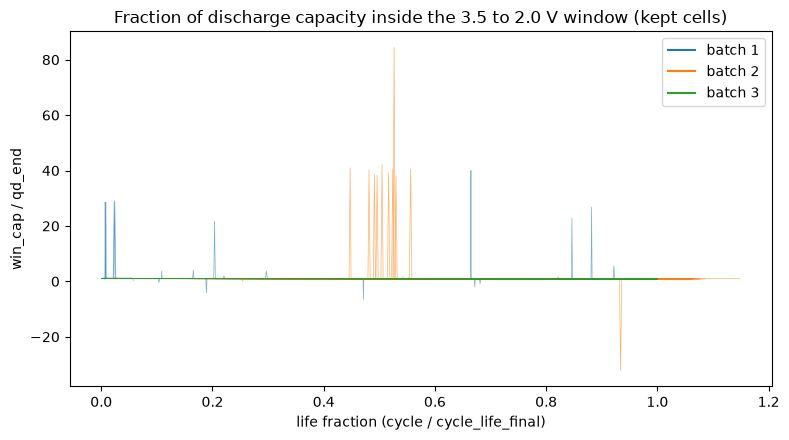

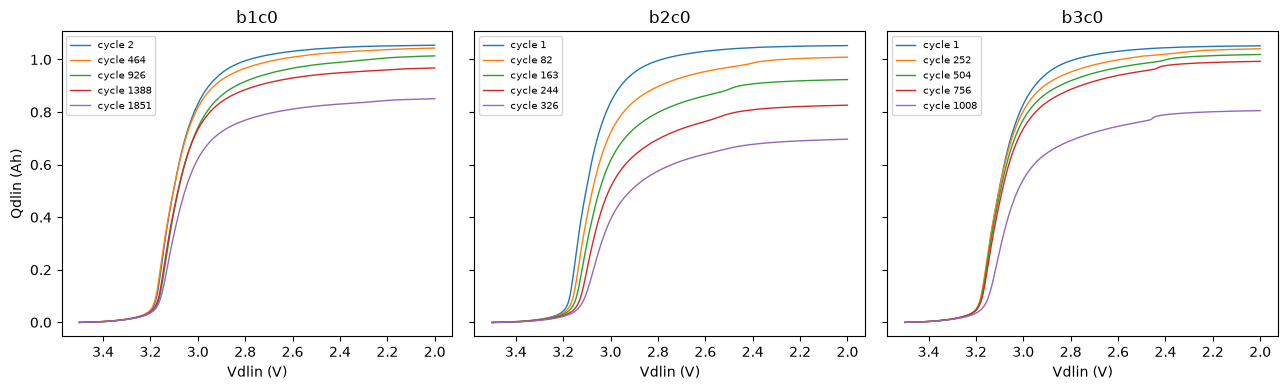

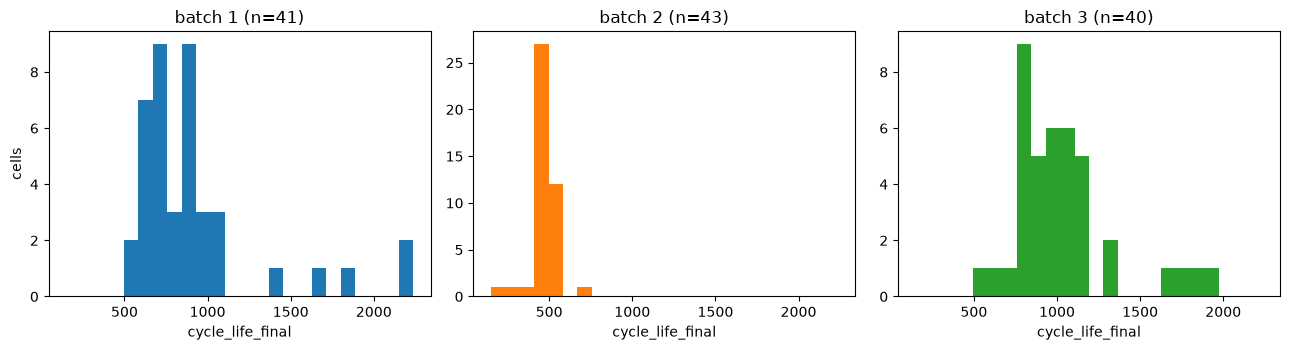

In [8]:
DECOMP = None
with guard("QD decomposition"):
    if CYC is None:
        raise RuntimeError("cycles table not assembled")
    TKm = np.load(PROC / "t_knots_f32.npy")
    life = CYC.cell_id.map(REGF.set_index("cell_id").cycle_life_final).to_numpy()
    lf = CYC.cycle_number.to_numpy() / life                         # life fraction (statistics and figures only)
    D = pd.DataFrame({
        "cell_id": CYC.cell_id, "batch": CYC.batch, "status": CYC.status, "life_frac": lf,
        "r_win": CYC.win_cap / CYC.qd_end, "r_v35": CYC.qd_at_v35 / CYC.qd_end, "r_cv": CYC.qd_cv_tail / CYC.qd_end,
        "dur_2v": TKm[:, -1].astype(np.float64),
        "saved_3p0": (TKm[:, -1] - TKm[:, 5]).astype(np.float64),
        "saved_2p5": (TKm[:, -1] - TKm[:, 10]).astype(np.float64),
        "saved_2p0": (TKm[:, -1] - TKm[:, 15]).astype(np.float64),
    })
    D = D[(~CYC.placeholder) & (CYC.status == "kept")].copy()
    D["decile"] = np.clip(np.floor(D.life_frac * 10), 0, 9).astype(int).astype(str)
    cols = {"r_win": "med_win_cap_over_qd_end", "r_v35": "med_qd_at_v35_over_qd_end", "r_cv": "med_qd_cv_tail_over_qd_end",
            "dur_2v": "med_dur_to_2v_min", "saved_3p0": "med_saved_min_close_3p0V",
            "saved_2p5": "med_saved_min_close_2p5V", "saved_2p0": "med_saved_min_close_2p0V"}
    parts = []
    for scope, sub in (("decile", D), ("all", D.assign(decile="all"))):
        gg = sub.groupby(["batch", "decile"])
        t = gg[list(cols)].median().rename(columns=cols)
        t.insert(0, "n_cycles", gg.size())
        parts.append(t.reset_index())
    allb = D.assign(batch=0, decile="all").groupby(["batch", "decile"])
    t = allb[list(cols)].median().rename(columns=cols)
    t.insert(0, "n_cycles", allb.size())
    parts.append(t.reset_index())
    DECOMP = pd.concat(parts, ignore_index=True)
    DECOMP["decile_sort"] = DECOMP.decile.replace({"all": "99"}).astype(int)
    DECOMP = DECOMP.sort_values(["batch", "decile_sort"]).drop(columns="decile_sort").reset_index(drop=True)
    DECOMP.rename(columns={"batch": "batch (0 = all)"}, inplace=True)
    print(DECOMP[DECOMP.decile == "all"].round(4).to_string(index=False))
    print(DECOMP[DECOMP["batch (0 = all)"] == 0].round(4).head(3).to_string(index=False))

    BCOL = {1: "tab:blue", 2: "tab:orange", 3: "tab:green"}

    # figure 1: window capacity fraction vs life fraction
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for cid, sub in D.groupby("cell_id", sort=False):
        ax.plot(sub.life_frac, sub.r_win, lw=0.5, alpha=0.6, color=BCOL[int(sub.batch.iloc[0])])
    for b in (1, 2, 3):
        ax.plot([], [], color=BCOL[b], label=f"batch {b}")
    ax.set_xlabel("life fraction (cycle / cycle_life_final)")
    ax.set_ylabel("win_cap / qd_end")
    ax.set_title("Fraction of discharge capacity inside the 3.5 to 2.0 V window (kept cells)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIG / "fig1_wincap_ratio_vs_life.png", dpi=130)
    plt.show()
    plt.close(fig)

    # figure 2: Qdlin vs Vdlin, 5 cycles of one cell per batch
    QLm = np.load(PROC / "qdlin_f32.npy", mmap_mode="r")
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
    for ax, b in zip(axes, (1, 2, 3)):
        cid = TABLE_CELLS.cell_id[(TABLE_CELLS.batch == b) & (TABLE_CELLS.status == "kept")].iloc[0]
        a0, a1 = ROWS[cid]
        valid = np.flatnonzero(~CYC.placeholder.to_numpy()[a0:a1])
        pick = valid[np.linspace(0, len(valid) - 1, 5).astype(int)]
        for p in pick:
            ax.plot(VDLIN_REF, np.asarray(QLm[a0 + p]), lw=1, label=f"cycle {int(CYC.cycle_number.iloc[a0 + p])}")
        ax.set_title(cid)
        ax.set_xlabel("Vdlin (V)")
        ax.invert_xaxis()
        ax.legend(fontsize=7)
    axes[0].set_ylabel("Qdlin (Ah)")
    fig.tight_layout()
    fig.savefig(FIG / "fig2_qdlin_vs_vdlin.png", dpi=130)
    plt.show()
    plt.close(fig)
    del QLm

    # figure 3: histogram of cycle_life_final per batch (kept cells)
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
    kf = REGF[REGF.status == "kept"]
    bins = np.linspace(kf.cycle_life_final.min(), kf.cycle_life_final.max(), 25)
    for ax, b in zip(axes, (1, 2, 3)):
        ax.hist(kf.cycle_life_final[kf.batch == b].dropna(), bins=bins, color=BCOL[b])
        ax.set_title(f"batch {b} (n={int((kf.batch == b).sum())})")
        ax.set_xlabel("cycle_life_final")
    axes[0].set_ylabel("cells")
    fig.tight_layout()
    fig.savefig(FIG / "fig3_cycle_life_hist.png", dpi=130)
    plt.show()
    plt.close(fig)

## 8. Qdlin reproduction test (exploratory)

In [9]:
RECIPE_RES = None
RECIPE_BEST = None
with guard("Qdlin reproduction test"):
    if CYC is None:
        raise RuntimeError("cycles table not assembled")
    tc = TABLE_CELLS.set_index("cell_id")
    names = ["a: interp onto Vdlin, subtract first", "b: interp onto Vdlin, no subtraction",
             "c: subtract Qd at 3.5 V crossing, then interp", "d (extra): (a) with monotone V"]

    def recipes(I, V, Qd):
        di = np.flatnonzero(I < DIS_I)
        Vd, Qdd = V[di], Qd[di]
        res = []
        r = np.interp(VDLIN_REF, Vd[::-1], Qdd[::-1])               # reversed so V is increasing
        res.append(r - r[0])
        res.append(r)
        hit = np.flatnonzero(Vd <= V_HIGH)
        q35 = Qdd[hit[0]] if hit.size else np.nan
        res.append(np.interp(VDLIN_REF, Vd[::-1], (Qdd - q35)[::-1]))
        rm = np.interp(VDLIN_REF, np.minimum.accumulate(Vd)[::-1], Qdd[::-1])
        res.append(rm - rm[0])
        return res

    recs = []
    QLm = np.load(PROC / "qdlin_f32.npy", mmap_mode="r")
    for b in (1, 2, 3):
        cid = next(c for c in TABLE_CELLS.cell_id[(TABLE_CELLS.batch == b) & (TABLE_CELLS.status == "kept") & ~TABLE_CELLS.cell_id.isin(list(STITCHED))])
        a0, a1 = ROWS[cid]
        sub = CYC.iloc[a0:a1]
        valid = np.flatnonzero(~sub.placeholder.to_numpy())
        pick = valid[np.linspace(0, len(valid) - 1, 5).astype(int)]
        with h5py.File(RAW_FILES[b], "r") as f:
            idx = int(tc.loc[cid, "idx"])
            cyc = get_group(f, "cycles", idx)
            Rr = {k: cyc[k][()].ravel() for k in ("I", "V", "Qd")}
            for p in pick:
                row = int(sub.pos_src.iloc[p])               # position in the source file (equal to p for non-stitched cells)
                I, V, Qd = (_rd(f, Rr[k][row]) for k in ("I", "V", "Qd"))
                stored = np.asarray(QLm[a0 + p], dtype=np.float64)
                for nm, rec in zip(names, recipes(I, V, Qd)):
                    err = np.abs(rec - stored)
                    recs.append(dict(cell_id=cid, cycle_number=int(sub.cycle_number.iloc[p]), recipe=nm,
                                     max_abs_err=float(np.nanmax(err)), mean_abs_err=float(np.nanmean(err))))
    del QLm
    RECIPE_RES = pd.DataFrame(recs)
    summ = RECIPE_RES.groupby("recipe").agg(max_abs_err=("max_abs_err", "max"), median_cycle_max_err=("max_abs_err", "median"),
                                           mean_abs_err=("mean_abs_err", "mean")).reset_index()
    RECIPE_BEST = summ.sort_values("max_abs_err").iloc[0].recipe
    print(summ.to_string(index=False))
    print("best recipe (lowest max abs error):", RECIPE_BEST)
    FINDINGS["recipe_summary"] = summ.to_dict("records")
    FINDINGS["recipe_best"] = RECIPE_BEST

                                       recipe  max_abs_err  median_cycle_max_err  mean_abs_err
         a: interp onto Vdlin, subtract first     0.096910              0.004656      0.000359
         b: interp onto Vdlin, no subtraction     0.096914              0.004665      0.000391
c: subtract Qd at 3.5 V crossing, then interp     0.096910              0.004656      0.000351
               d (extra): (a) with monotone V     0.005564              0.003525      0.000349
best recipe (lowest max abs error): d (extra): (a) with monotone V


## 9. Per-cycle quality flags

In [10]:
CAUSAL_FLAGS = ["flag_placeholder", "flag_qdlin_bad", "flag_diag_suspect", "flag_ir_nonpos", "flag_qd_mismatch"]
OFFLINE_FLAGS = ["flag_qdqc_gap", "flag_qd_spike"]       # look at neighbours or QC: label use only, never for serving
FLAG_LISTS = {}


def ranges(nums):
    nums = sorted(set(int(x) for x in nums))
    out, s, p = [], None, None
    for x in nums:
        if s is None:
            s = p = x
        elif x == p + 1:
            p = x
        else:
            out.append(f"{s}" if s == p else f"{s}-{p}")
            s = p = x
    if s is not None:
        out.append(f"{s}" if s == p else f"{s}-{p}")
    return ",".join(out)


with guard("quality flags"):
    if CYC is None:
        raise RuntimeError("cycles table not assembled")
    nonph = ~CYC.placeholder.to_numpy()
    nonfinite, mono_bad = qdlin_status()
    CYC["flag_placeholder"] = CYC.placeholder.to_numpy()
    CYC["flag_qdlin_bad"] = nonph & (nonfinite | (CYC.qdlin_len.to_numpy() != N_QDLIN) | mono_bad)
    med_n = CYC.groupby("cell_id")["n_samples"].transform(lambda s: s.astype("float64").median())
    nsam = CYC.n_samples.astype("float64")
    bad_i = (CYC.i_dis_median + 4.0).abs() > 0.1
    bad_i = bad_i | CYC.i_dis_median.isna()
    bad_n = ((nsam - med_n).abs() / med_n) > 0.5
    CYC["flag_diag_suspect"] = nonph & (bad_i.to_numpy() | bad_n.fillna(False).to_numpy())
    CYC["flag_ir_nonpos"] = nonph & (CYC.ir <= 0).to_numpy()
    CYC["flag_qd_mismatch"] = nonph & ((CYC.qd_end - CYC.qd_sum).abs() > 1e-5).to_numpy()
    # offline flags
    CYC["flag_qdqc_gap"] = nonph & ((CYC.qd_sum - CYC.qc_sum).abs() > 0.02).to_numpy()
    # centred rolling median over 11 cycles, computed within each stitched segment so the junction is not smoothed over
    roll = CYC.groupby(["cell_id", "segment"], sort=False)["qd_sum"].transform(
        lambda s: s.rolling(11, center=True, min_periods=1).median())
    CYC["flag_qd_spike"] = nonph & ((CYC.qd_sum - roll).abs() > 0.03).to_numpy()
    for fl in CAUSAL_FLAGS + OFFLINE_FLAGS:
        CYC[fl] = CYC[fl].astype(bool)
    CYC.to_parquet(PROC / "cycles_table.parquet", index=False)

    rows = []
    for fl in CAUSAL_FLAGS + OFFLINE_FLAGS:
        kind = "causal" if fl in CAUSAL_FLAGS else "offline (label use only)"
        for scope, m in (("ALL", np.ones(len(CYC), bool)), ("b1", CYC.batch.eq(1).to_numpy()),
                         ("b2", CYC.batch.eq(2).to_numpy()), ("b3", CYC.batch.eq(3).to_numpy())):
            sel = CYC[fl].to_numpy() & m
            rows.append(dict(flag=fl, kind=kind, scope=scope, n_cycles=int(sel.sum()),
                             n_cells=int(CYC.cell_id[sel].nunique()), pct_of_cycles=100.0 * sel.sum() / max(1, int(m.sum()))))
    FLAGSUM = pd.DataFrame(rows)
    print(FLAGSUM.round(3).to_string(index=False))

    for fl in ("flag_qdqc_gap", "flag_qd_spike", "flag_diag_suspect"):
        sub = CYC[CYC[fl]]
        FLAG_LISTS[fl] = {c: ranges(s.cycle_number) for c, s in sub.groupby("cell_id", sort=False)}
    for fl in ("flag_qdqc_gap", "flag_qd_spike"):
        print(f"\n{fl}: {len(FLAG_LISTS[fl])} cells")
        for c, s in FLAG_LISTS[fl].items():
            print(f"  {c}: {s[:150]}")
    ds = CYC[CYC.flag_diag_suspect]
    cn_counts = ds.groupby("cycle_number").cell_id.nunique().sort_values(ascending=False)
    FINDINGS["diag_top_cycles"] = {int(k): int(v) for k, v in cn_counts.head(12).items()}
    print("\nflag_diag_suspect: cycle numbers shared by most cells (cycle -> n cells):", FINDINGS["diag_top_cycles"])
    print("cells with flag_diag_suspect:", ds.cell_id.nunique())
    for c, s in list(FLAG_LISTS["flag_diag_suspect"].items())[:40]:
        print(f"  {c}: {s[:100]}")

    # known QD spikes (Phase 1)
    kn = {}
    for c, v in KNOWN_SPIKES.items():
        if c in ROWS:
            a0, a1 = ROWS[c]
            kn[c] = (float(CYC.qd_sum.iloc[a0:a1].max()), c in FLAG_LISTS["flag_qd_spike"])
    check("known QD spikes present and flagged (b1c0, b1c18, b2c12, b2c44)",
          all(mx >= 1.4 and fl for mx, fl in kn.values()) and len(kn) == 4, str({k: (round(a, 3), b) for k, (a, b) in kn.items()}),
          severity="WARN")
    FLAGSUM.to_csv(OUT / "flag_summary.csv", index=False)

             flag                     kind scope  n_cycles  n_cells  pct_of_cycles
 flag_placeholder                   causal   ALL        46       46          0.044
 flag_placeholder                   causal    b1        46       46          0.109
 flag_placeholder                   causal    b2         0        0          0.000
 flag_placeholder                   causal    b3         0        0          0.000
   flag_qdlin_bad                   causal   ALL       289       44          0.275
   flag_qdlin_bad                   causal    b1        46       24          0.109
   flag_qdlin_bad                   causal    b2       239       16          1.110
   flag_qdlin_bad                   causal    b3         4        4          0.010
flag_diag_suspect                   causal   ALL        88        8          0.084
flag_diag_suspect                   causal    b1        52        2          0.123
flag_diag_suspect                   causal    b2        18        4          0.084
flag

## 10. Save and report

In [11]:
def _json_default(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, Path):
        return str(o)
    return str(o)


with guard("save csv and json outputs"):
    JUNC.to_csv(OUT / "junction_steps.csv", index=False)
    if DECOMP is not None:
        DECOMP.to_csv(OUT / "qd_decomposition.csv", index=False)
    if "FLAGSUM" in globals():
        FLAGSUM.to_csv(OUT / "flag_summary.csv", index=False)
    counts = Counter(c["status"] for c in CHECKS)
    report = {
        "phase": 2, "root": str(ROOT), "runtime_seconds": time.time() - T0,
        "config": dict(SEED=SEED, NOMINAL_AH=NOMINAL_AH, EOL_AH=EOL_AH, V_HIGH=V_HIGH, V_LOW=V_LOW, FORCE_REEXTRACT=FORCE_REEXTRACT),
        "raw_files": RAW_HASH, "extraction": EXTRACT,
        "check_counts": dict(counts), "checks": CHECKS, "errors": ERRORS,
        "findings": FINDINGS, "flag_lists": FLAG_LISTS,
        "junctions": JUNC.to_dict("records"),
    }
    with open(OUT / "verification_report.json", "w", encoding="utf-8") as fh:
        json.dump(report, fh, indent=2, default=_json_default)

In [12]:
def _blk(title, fn):
    try:
        return [title] + [("  " + l) for l in fn()]
    except Exception as e:
        return [title, f"  <unavailable: {type(e).__name__}: {e}>"]


def _trunc(s, n=150):
    s = str(s).replace("\n", " ")
    return s if len(s) <= n else s[:n - 3] + "..."


def b_extraction():
    return [f"cells: new={EXTRACT['new']}, reused={EXTRACT['reused']}, failed={len(EXTRACT['failed'])} {EXTRACT['failed'][:5]}",
            f"extract time this run: {EXTRACT['seconds']:.0f} s; low-RAM (<2 GB) cell steps: {EXTRACT['low_ram_cells']}",
            f"cache: {EXTRACT['cache_files']} files, {EXTRACT['cache_mb']:.0f} MB"]


def b_registry():
    t = REG.groupby(["status", "batch"]).size().unstack(fill_value=0)
    t["total"] = t.sum(axis=1)
    l = t.to_string().split("\n")
    l.append(f"table cells {CYC.cell_id.nunique()}, rows {len(CYC)}; cycles by batch {FINDINGS.get('cycles_by_batch')}; "
             f"non-placeholder by batch {FINDINGS.get('nonplaceholder_by_batch')}")
    return l


def b_junction():
    t = JUNC[["cell_id", "continuation", "junction_pos", "n_b1", "n_b2", "qd_last_seg0", "qd_first_seg1", "step_ah",
              "step_pp_nominal", "step_over_med", "cycle_life_stitched"]].round(4)
    return t.to_string(index=False).split("\n")


def b_checks():
    l = []
    for st in ("FAIL", "WARN", "PASS"):
        sel = [c for c in CHECKS if c["status"] == st]
        l.append(f"{st} ({len(sel)})")
        for c in sel:
            l.append(f"  - {c['name']}" + (f": {_trunc(c['detail'])}" if st != "PASS" or len(c["detail"]) < 60 else ""))
    return l


def b_flags():
    t = FLAGSUM.pivot_table(index="flag", columns="scope", values="n_cycles", aggfunc="sum")[["ALL", "b1", "b2", "b3"]]
    t["cells(ALL)"] = FLAGSUM[FLAGSUM.scope == "ALL"].set_index("flag").n_cells
    t = t.reindex(CAUSAL_FLAGS + OFFLINE_FLAGS)
    l = t.astype(int).to_string().split("\n")
    for fl in ("flag_qdqc_gap", "flag_qd_spike"):
        d = FLAG_LISTS.get(fl, {})
        l.append(f"{fl}: {len(d)} cells; " + "; ".join(f"{c}[{_trunc(s, 40)}]" for c, s in list(d.items())[:12]) + (" ..." if len(d) > 12 else ""))
    l.append(f"flag_diag_suspect most shared cycle numbers (cycle: n cells): {FINDINGS.get('diag_top_cycles')}")
    l.append("(offline flags use neighbours or QC: label use only; full lists in verification_report.json)")
    return l


def b_decomp():
    t = DECOMP[DECOMP.decile == "all"].drop(columns="decile").round(4)
    return t.to_string(index=False).split("\n")


def b_recipes():
    l = [f"{r['recipe']}: max {r['max_abs_err']:.4g}, median cycle max {r['median_cycle_max_err']:.4g}, mean {r['mean_abs_err']:.4g}"
         for r in FINDINGS["recipe_summary"]]
    l.append(f"best: {FINDINGS['recipe_best']}")
    return l


def b_fields():
    l = [_trunc(x, 170) for x in FINDINGS.get("inspect", [])[:18]]
    l.append(_trunc(FINDINGS.get("policy_message", ""), 220))
    l.append(f"Vdlin max abs diff across cells/files: {FINDINGS.get('vdlin_maxdiff')}")
    return l


def b_errors():
    return [f"{e['where']}: {_trunc(e['error'], 200)}" for e in ERRORS] or ["none"]


def b_artifacts():
    paths = [PROC / "cycles_table.parquet", PROC / "qdlin_f32.npy", PROC / "t_knots_f32.npy", PROC / "cell_registry_final.csv",
             OUT / "phase2_report.txt", OUT / "verification_report.json", OUT / "junction_steps.csv", OUT / "flag_summary.csv",
             OUT / "qd_decomposition.csv"] + sorted(FIG.glob("*.png"))
    return [f"{p.relative_to(ROOT).as_posix()}  {human(p.stat().st_size) if p.exists() else 'MISSING (this file, written now)' if p.name == 'phase2_report.txt' else 'MISSING'}"
            for p in paths]


def build_report():
    cnt = Counter(c["status"] for c in CHECKS)
    L = ["PHASE 2 REPORT", "=" * 14,
         f"runtime: {(time.time() - T0) / 60:.1f} min; checks PASS {cnt['PASS']} / WARN {cnt['WARN']} / FAIL {cnt['FAIL']}; errors {len(ERRORS)}"]
    L += _blk("EXTRACTION", b_extraction)
    L += _blk("REGISTRY", b_registry)
    L += _blk("JUNCTIONS (steps use summary QD)", b_junction)
    L += _blk("CHECKS", b_checks)
    L += _blk("FLAGS (cycles per scope)", b_flags)
    L += _blk("QD DECOMPOSITION medians per batch (0 = all)", b_decomp)
    L += _blk("QDLIN RECIPES (3 cells x 5 cycles, Ah)", b_recipes)
    L += _blk("BARCODE / CHANNEL_ID / POLICY FIELDS", b_fields)
    L += _blk("RECORDED ERRORS", b_errors)
    L += _blk("ARTIFACTS", b_artifacts)
    return "\n".join(L)


_txt = build_report()
(OUT / "phase2_report.txt").write_text(_txt, encoding="utf-8")      # first write so the artifact list can show its size
_txt = build_report()
(OUT / "phase2_report.txt").write_text(_txt, encoding="utf-8")
print(_txt)

PHASE 2 REPORT
runtime: 4.5 min; checks PASS 49 / WARN 7 / FAIL 0; errors 0
EXTRACTION
  cells: new=134, reused=0, failed=0 []
  extract time this run: 239 s; low-RAM (<2 GB) cell steps: 0
  cache: 134 files, 420 MB
REGISTRY
  batch                   1   2   3  total
  status                                  
  excluded_continuation   0   5   0      5
  excluded_noisy          0   0   6      6
  kept                   41  43  40    124
  sensitivity             5   0   0      5
  table cells 129, rows 104971; cycles by batch {1: 42204, 2: 21527, 3: 41240}; non-placeholder by batch {1: 42158, 2: 21527, 3: 41240}
JUNCTIONS (steps use summary QD)
  cell_id continuation  junction_pos  n_b1  n_b2  qd_last_seg0  qd_first_seg1  step_ah  step_pp_nominal  step_over_med  cycle_life_stitched
     b1c0         b2c7          1189  1189   662        1.0262         1.0219  -0.0043          -0.3896        12.8801               1852.0
     b1c1         b2c8          1178  1178   981        1.0382      